# LSTM 电影评论情感分析：改进版

改进版直接沿用原 Notebook 的数据读取、清理、词表、整数序列、LSTM 主体和训练配置。
修改集中在实验控制与评估流程，没有引入外部项目包：

1. 固定随机种子，并让两组模型使用相同的数据顺序；
2. 把真实序列长度交给 LSTM，用 `pack_padded_sequence` 排除 padding；
3. 随机 Embedding 与 GloVe Embedding 都冻结，统一实验条件；
4. 每轮验证后保存验证集 Accuracy 最好的 checkpoint；
5. 用 scikit-learn 计算指标，并保存训练历史、图表和指标 JSON。

> 改进后仍然使用原项目的 80% / 10% / 10% 划分。这个改进版回答的是
> “在原数据划分下把对照做得更公平后，结果如何”，不是重建一个全新的深度学习项目。


In [1]:
import collections
import glob
import json
import os
import random
import re
import time
import warnings
from pathlib import Path

import datasets
import matplotlib.pyplot as plt
import nltk
import numpy as np
import torch
import torch.nn as nn
from bs4 import BeautifulSoup
from datasets import Dataset, DatasetDict
from nltk.tokenize import word_tokenize
from sklearn.metrics import (
    accuracy_score,
    confusion_matrix,
    f1_score,
    precision_score,
    recall_score,
    roc_auc_score,
    roc_curve,
)
from torch.nn.utils.rnn import pack_padded_sequence, pad_sequence
from torch.utils.data import DataLoader

warnings.filterwarnings("ignore", category=UserWarning)
datasets.disable_progress_bar()
datasets.disable_caching()

SEED = 42
EPOCHS = 10
BATCH_SIZE = 32
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
ARTIFACT_DIR = Path("artifacts")
ARTIFACT_DIR.mkdir(exist_ok=True)

print("device:", DEVICE)
if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

for package, resource in (("corpora", "stopwords"), ("tokenizers", "punkt")):
    try:
        nltk.data.find(f"{package}/{resource}")
    except LookupError:
        nltk.download(resource, quiet=True)


device: cuda
GPU: NVIDIA GeForce RTX 4060 Laptop GPU


## 1. 数据划分与清理

数据读取、80/10/10 划分、HTML 清理、小写化、停用词删除和 10,000 词词表
均与原版一致，便于把变化集中在实验设计本身。


In [2]:
def load_and_split_data(data_path):
    data, labels = [], []
    for label, label_value in (("pos", 1), ("neg", 0)):
        for file_name in glob.glob(f"{data_path}/{label}/*.txt"):
            with open(file_name, "r", encoding="utf-8") as handle:
                data.append(handle.read().strip())
            labels.append(label_value)

    dataset = Dataset.from_dict({"text": data, "label": labels})
    train_test = dataset.train_test_split(test_size=0.2, seed=42)
    validation_test = train_test["test"].train_test_split(
        test_size=0.5, seed=42
    )
    return DatasetDict(
        {
            "train": train_test["train"],
            "validation": validation_test["train"],
            "test": validation_test["test"],
        }
    )


def find_data_path(env_name, relative_path):
    env_value = os.getenv(env_name)
    if env_value and Path(env_value).exists():
        return Path(env_value)
    for parent in [Path.cwd(), *Path.cwd().parents]:
        candidate = parent / relative_path
        if candidate.exists():
            return candidate
    raise FileNotFoundError(
        f"找不到 {relative_path}，请设置环境变量 {env_name} 为实际路径。"
    )


def preprocess_text(text):
    stop_words = nltk.corpus.stopwords.words("english")
    text = BeautifulSoup(text, "html.parser").get_text()
    text = text.lower()
    text = re.sub(r"[^a-z\s]", "", text)
    return [
        token
        for token in word_tokenize(text)
        if token not in stop_words
    ]


root_dir = find_data_path("IMDB_TRAIN_DIR", "data/aclImdb/train")
dataset = load_and_split_data(root_dir)
dataset = dataset.map(
    lambda example: {"tokens": preprocess_text(example["text"])},
    batched=False,
    num_proc=1,
)
print({name: len(split) for name, split in dataset.items()})
print("First 30 tokens:", dataset["train"][0]["tokens"][:30])


{'train': 20000, 'validation': 2500, 'test': 2500}
First 30 tokens: ['waaaaay', 'much', 'frustrating', 'watch', 'waiting', 'whole', 'damn', 'movie', 'end', 'finally', 'get', 'answers', 'ive', 'end', 'nothing', 'huuuge', 'neonsign', 'question', 'mark', 'head', 'havent', 'seen', 'bad', 'acting', 'nonsense', 'movie', 'long', 'long', 'time', 'whats']


In [3]:
def build_vocab(token_list, max_size=10000):
    counter = collections.Counter(
        token for tokens in token_list for token in tokens
    )
    vocab_tokens = ["<pad>", "<unk>"] + [
        token for token, _ in counter.most_common(max_size - 2)
    ]
    stoi = {token: index for index, token in enumerate(vocab_tokens)}
    itos = {index: token for token, index in stoi.items()}
    return stoi, itos


def vectorize(tokens, stoi):
    return [stoi.get(token, stoi["<unk>"]) for token in tokens]


stoi, itos = build_vocab(dataset["train"]["tokens"])
dataset = dataset.map(
    lambda example: {
        "integer_sequence": vectorize(example["tokens"], stoi)
    },
    batched=False,
    num_proc=1,
)
print("Vocabulary size:", len(stoi))
print("First five tokens:", list(stoi.items())[:5])


Vocabulary size: 10000
First five tokens: [('<pad>', 0), ('<unk>', 1), ('movie', 2), ('film', 3), ('one', 4)]


In [4]:
def load_glove_embeddings(glove_file, stoi, embedding_dim=300, seed=42):
    rng = np.random.default_rng(seed)
    embedding = rng.normal(size=(len(stoi), embedding_dim)).astype(np.float32)
    found = 0
    with open(glove_file, "r", encoding="utf-8") as handle:
        for line in handle:
            parts = line.rstrip().split(" ")
            index = stoi.get(parts[0])
            if index is not None:
                embedding[index] = np.asarray(parts[1:], dtype=np.float32)
                found += 1
    return torch.tensor(embedding), found


glove_file = find_data_path(
    "GLOVE_PATH", "data/glove/glove.6B.300d.txt"
)
pretrained_embeddings, glove_found = load_glove_embeddings(
    glove_file, stoi, seed=SEED
)
print("Embedding shape:", tuple(pretrained_embeddings.shape))
print(f"GloVe coverage: {glove_found}/{len(stoi)} = {glove_found / len(stoi):.2%}")


Embedding shape: (10000, 300)
GloVe coverage: 9851/10000 = 98.51%


## 2. 动态 padding 与真实长度

padding 只是为了让同一个 batch 能组成矩形张量，不是评论里的真实单词。
改进版把 `lengths` 一并传给模型，再用 `pack_padded_sequence` 排除 pad 时间步。


In [5]:
def seed_everything(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False


def collate_fn(batch):
    sequences = [
        torch.tensor(item["integer_sequence"], dtype=torch.long)
        for item in batch
    ]
    lengths = torch.tensor(
        [len(sequence) for sequence in sequences], dtype=torch.long
    )
    labels = torch.tensor(
        [item["label"] for item in batch], dtype=torch.long
    )
    padded_sequences = pad_sequence(
        sequences,
        batch_first=True,
        padding_value=stoi["<pad>"],
    )
    return padded_sequences, lengths, labels


def make_loaders(seed):
    train_generator = torch.Generator().manual_seed(seed)
    train_loader = DataLoader(
        dataset["train"],
        batch_size=BATCH_SIZE,
        shuffle=True,
        collate_fn=collate_fn,
        generator=train_generator,
    )
    val_loader = DataLoader(
        dataset["validation"],
        batch_size=BATCH_SIZE,
        shuffle=False,
        collate_fn=collate_fn,
    )
    test_loader = DataLoader(
        dataset["test"],
        batch_size=BATCH_SIZE,
        shuffle=False,
        collate_fn=collate_fn,
    )
    return train_loader, val_loader, test_loader


sample_train_loader, _, _ = make_loaders(SEED)
sample_inputs, sample_lengths, sample_labels = next(iter(sample_train_loader))
print("Input batch shape:", sample_inputs.shape)
print("Lengths:", sample_lengths[:10].tolist())
print("Labels shape:", sample_labels.shape)


Input batch shape: torch.Size([32, 307])
Lengths: [70, 64, 87, 207, 176, 82, 307, 277, 91, 82]
Labels shape: torch.Size([32])


## 3. 保持原结构的 LSTM

模型仍然是单层单向 LSTM、300 维 Embedding、512 维 hidden state、Dropout 0.5
和二维输出。唯一的结构性修改是把真实 lengths 交给 packing。


In [6]:
class LSTM(nn.Module):
    def __init__(
        self,
        vocab_size,
        embedding_dim,
        hidden_dim,
        output_dim,
        dropout_rate=0.5,
        embedding_type="random",
        pretrained_embedding=None,
        freeze_embedding=True,
    ):
        super().__init__()

        # 先初始化两组实验共享的层，避免随机 Embedding 多消耗一次随机数
        # 后让 LSTM/Linear 的初始权重不一致。
        self.lstm = nn.LSTM(
            input_size=embedding_dim,
            hidden_size=hidden_dim,
            num_layers=1,
            bidirectional=False,
            dropout=0.0,
            batch_first=True,
        )
        self.dropout = nn.Dropout(dropout_rate)
        self.fc = nn.Linear(hidden_dim, output_dim)

        if embedding_type == "random":
            self.embedding = nn.Embedding(vocab_size, embedding_dim)
            self.embedding.weight.requires_grad_(not freeze_embedding)
        elif embedding_type == "pretrained":
            self.embedding = nn.Embedding.from_pretrained(
                pretrained_embedding,
                freeze=freeze_embedding,
            )
        else:
            raise ValueError("embedding_type must be 'random' or 'pretrained'")

    def forward(self, inputs, lengths):
        embedded = self.embedding(inputs)
        packed_embedded = pack_padded_sequence(
            embedded,
            lengths.cpu(),
            batch_first=True,
            enforce_sorted=False,
        )
        _, (hidden, _) = self.lstm(packed_embedded)
        hidden = self.dropout(hidden[-1])
        return self.fc(hidden)


## 4. 自动指标与最佳 checkpoint

每个 epoch 都在验证集上计算 Loss、Accuracy、Precision、Recall、F1 和 ROC-AUC。
按验证集 Accuracy 选最佳轮次；Accuracy 相同时选验证 Loss 更低的轮次。
测试集不参与 checkpoint 选择。


In [7]:
def calculate_metrics(model, loader, criterion):
    model.eval()
    losses = []
    targets = []
    predictions = []
    probabilities = []

    with torch.no_grad():
        for inputs, lengths, labels in loader:
            inputs = inputs.to(DEVICE)
            lengths = lengths.to(DEVICE)
            labels = labels.to(DEVICE)

            logits = model(inputs, lengths)
            losses.append(criterion(logits, labels).item())
            targets.extend(labels.cpu().tolist())
            predictions.extend(logits.argmax(dim=1).cpu().tolist())
            probabilities.extend(
                torch.softmax(logits, dim=1)[:, 1].cpu().tolist()
            )

    return {
        "loss": float(np.mean(losses)),
        "accuracy": float(accuracy_score(targets, predictions)),
        "precision": float(
            precision_score(targets, predictions, zero_division=0)
        ),
        "recall": float(recall_score(targets, predictions, zero_division=0)),
        "f1": float(f1_score(targets, predictions, zero_division=0)),
        "roc_auc": float(roc_auc_score(targets, probabilities)),
        "confusion_matrix": confusion_matrix(
            targets, predictions, labels=[0, 1]
        ).tolist(),
        "targets": targets,
        "predictions": predictions,
        "probabilities": probabilities,
    }


def train_model(
    model,
    train_loader,
    val_loader,
    optimizer,
    criterion,
    num_epochs=EPOCHS,
):
    model.to(DEVICE)
    history = {
        "train_loss": [],
        "val_loss": [],
        "val_accuracy": [],
        "val_precision": [],
        "val_recall": [],
        "val_f1": [],
        "val_roc_auc": [],
    }
    best_state = None
    best_epoch = 0
    best_val_accuracy = -1.0
    best_val_loss = float("inf")

    for epoch in range(1, num_epochs + 1):
        model.train()
        start = time.time()
        batch_losses = []

        for inputs, lengths, labels in train_loader:
            inputs = inputs.to(DEVICE)
            lengths = lengths.to(DEVICE)
            labels = labels.to(DEVICE)

            optimizer.zero_grad()
            logits = model(inputs, lengths)
            loss = criterion(logits, labels)
            loss.backward()
            optimizer.step()
            batch_losses.append(loss.item())

        val_metrics = calculate_metrics(model, val_loader, criterion)
        train_loss = float(np.mean(batch_losses))

        history["train_loss"].append(train_loss)
        history["val_loss"].append(val_metrics["loss"])
        for metric in (
            "accuracy",
            "precision",
            "recall",
            "f1",
            "roc_auc",
        ):
            history[f"val_{metric}"].append(val_metrics[metric])

        is_better = (
            val_metrics["accuracy"] > best_val_accuracy
            or (
                val_metrics["accuracy"] == best_val_accuracy
                and val_metrics["loss"] < best_val_loss
            )
        )
        if is_better:
            best_val_accuracy = val_metrics["accuracy"]
            best_val_loss = val_metrics["loss"]
            best_epoch = epoch
            best_state = {
                name: tensor.detach().cpu().clone()
                for name, tensor in model.state_dict().items()
            }

        print(
            f"Epoch {epoch:02d}: train_loss={train_loss:.4f}, "
            f"val_loss={val_metrics['loss']:.4f}, "
            f"val_acc={val_metrics['accuracy']:.4f}, "
            f"val_f1={val_metrics['f1']:.4f}, "
            f"val_auc={val_metrics['roc_auc']:.4f}, "
            f"time={time.time() - start:.1f}s"
        )

    model.load_state_dict(best_state)
    return history, best_epoch, best_state


## 5. 运行受控对照

两种模型在每次运行前都重置为同一个随机种子，DataLoader 也使用相同种子。
两者的 Embedding 都冻结，因此本次比较只改变“Embedding 使用随机初始化还是
GloVe 初始化”这一项。


In [8]:
def run_experiment(embedding_type):
    seed_everything(SEED)
    train_loader, val_loader, test_loader = make_loaders(SEED)

    model = LSTM(
        vocab_size=len(stoi),
        embedding_dim=300,
        hidden_dim=512,
        output_dim=2,
        dropout_rate=0.5,
        embedding_type=embedding_type,
        pretrained_embedding=(
            pretrained_embeddings if embedding_type == "pretrained" else None
        ),
        freeze_embedding=True,
    )
    optimizer = torch.optim.Adam(model.parameters(), lr=0.0008)
    criterion = nn.CrossEntropyLoss()

    print(
        f"\n=== {embedding_type}: frozen embedding, seed={SEED} ==="
    )
    history, best_epoch, best_state = train_model(
        model,
        train_loader,
        val_loader,
        optimizer,
        criterion,
    )

    checkpoint_path = ARTIFACT_DIR / f"best_{embedding_type}.pt"
    torch.save(
        {
            "model_state_dict": best_state,
            "best_epoch": best_epoch,
            "embedding_type": embedding_type,
            "seed": SEED,
        },
        checkpoint_path,
    )
    test_metrics = calculate_metrics(model, test_loader, criterion)
    test_metrics["best_epoch"] = best_epoch
    test_metrics["checkpoint"] = str(checkpoint_path)

    print(f"Best validation epoch: {best_epoch}")
    print(
        "Test: "
        f"acc={test_metrics['accuracy']:.4f}, "
        f"precision={test_metrics['precision']:.4f}, "
        f"recall={test_metrics['recall']:.4f}, "
        f"f1={test_metrics['f1']:.4f}, "
        f"auc={test_metrics['roc_auc']:.4f}"
    )
    return {
        "history": history,
        "test_metrics": test_metrics,
        "best_state": best_state,
    }


random_result = run_experiment("random")



=== random: frozen embedding, seed=42 ===


Epoch 01: train_loss=0.6140, val_loss=0.5498, val_acc=0.7192, val_f1=0.6872, val_auc=0.7937, time=16.8s


Epoch 02: train_loss=0.4700, val_loss=0.4554, val_acc=0.7952, val_f1=0.7874, val_auc=0.8707, time=16.5s


Epoch 03: train_loss=0.3744, val_loss=0.4206, val_acc=0.8164, val_f1=0.8165, val_auc=0.8923, time=16.2s


Epoch 04: train_loss=0.2754, val_loss=0.4346, val_acc=0.7996, val_f1=0.8024, val_auc=0.8837, time=16.4s


Epoch 05: train_loss=0.1838, val_loss=0.4892, val_acc=0.8072, val_f1=0.7968, val_auc=0.8930, time=16.6s


... (2 outputs left out)

Epoch 08: train_loss=0.0746, val_loss=0.6642, val_acc=0.8064, val_f1=0.8066, val_auc=0.8894, time=16.4s


Epoch 09: train_loss=0.0339, val_loss=0.7724, val_acc=0.8216, val_f1=0.8157, val_auc=0.8943, time=16.4s


Epoch 10: train_loss=0.0204, val_loss=0.8152, val_acc=0.8136, val_f1=0.8173, val_auc=0.8953, time=16.7s


Best validation epoch: 7
Test: acc=0.8340, precision=0.8413, recall=0.8273, f1=0.8342, auc=0.9093


In [9]:
glove_result = run_experiment("pretrained")



=== pretrained: frozen embedding, seed=42 ===


Epoch 01: train_loss=0.5304, val_loss=0.4989, val_acc=0.7604, val_f1=0.7133, val_auc=0.8607, time=17.2s


Epoch 02: train_loss=0.4196, val_loss=0.3880, val_acc=0.8388, val_f1=0.8360, val_auc=0.9165, time=16.4s


Epoch 03: train_loss=0.3593, val_loss=0.3823, val_acc=0.8240, val_f1=0.8079, val_auc=0.9163, time=16.9s


Epoch 04: train_loss=0.3161, val_loss=0.3594, val_acc=0.8576, val_f1=0.8621, val_auc=0.9338, time=16.8s


Epoch 05: train_loss=0.2774, val_loss=0.3463, val_acc=0.8484, val_f1=0.8399, val_auc=0.9290, time=16.8s


... (2 outputs left out)

Epoch 08: train_loss=0.1452, val_loss=0.4725, val_acc=0.8128, val_f1=0.8308, val_auc=0.9185, time=16.6s


Epoch 09: train_loss=0.0991, val_loss=0.4893, val_acc=0.8488, val_f1=0.8465, val_auc=0.9209, time=16.5s


Epoch 10: train_loss=0.0692, val_loss=0.5587, val_acc=0.8452, val_f1=0.8430, val_auc=0.9147, time=16.6s


Best validation epoch: 7
Test: acc=0.8632, precision=0.8840, recall=0.8391, f1=0.8610, auc=0.9376


## 6. 训练曲线与结果


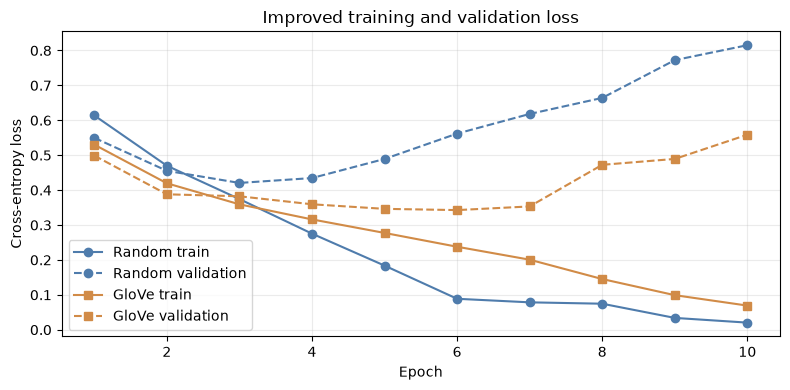

In [10]:
plt.figure(figsize=(8, 4))
epochs = range(1, EPOCHS + 1)
plt.plot(
    epochs,
    random_result["history"]["train_loss"],
    marker="o",
    label="Random train",
    color="#4f7cac",
)
plt.plot(
    epochs,
    random_result["history"]["val_loss"],
    marker="o",
    linestyle="--",
    label="Random validation",
    color="#4f7cac",
)
plt.plot(
    epochs,
    glove_result["history"]["train_loss"],
    marker="s",
    label="GloVe train",
    color="#d18b47",
)
plt.plot(
    epochs,
    glove_result["history"]["val_loss"],
    marker="s",
    linestyle="--",
    label="GloVe validation",
    color="#d18b47",
)
plt.xlabel("Epoch")
plt.ylabel("Cross-entropy loss")
plt.title("Improved training and validation loss")
plt.legend()
plt.grid(True, alpha=0.25)
plt.tight_layout()
plt.savefig(ARTIFACT_DIR / "loss_curves.png", dpi=160, bbox_inches="tight")
plt.show()


Improved model comparison
Metric        Random    GloVe
--------------------------------
accuracy     0.8340    0.8632
precision    0.8413    0.8840
recall       0.8273    0.8391
f1           0.8342    0.8610
roc_auc      0.9093    0.9376
Best epoch     7         7


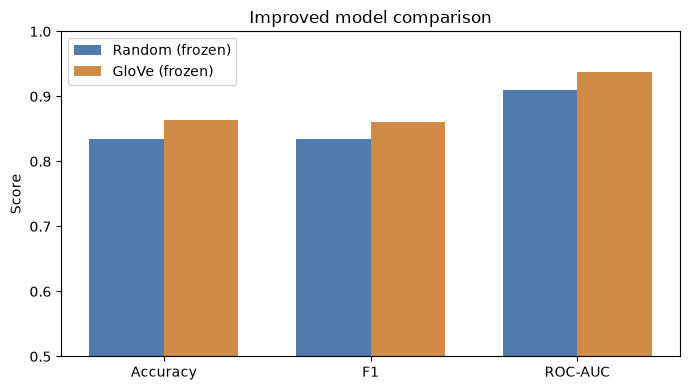

In [11]:
comparison = {
    "Random": random_result["test_metrics"],
    "GloVe": glove_result["test_metrics"],
}

print("Improved model comparison")
print("Metric        Random    GloVe")
print("--------------------------------")
for metric in ("accuracy", "precision", "recall", "f1", "roc_auc"):
    print(
        f"{metric:<12} "
        f"{comparison['Random'][metric]:.4f}    "
        f"{comparison['GloVe'][metric]:.4f}"
    )
print(
    "Best epoch     "
    f"{comparison['Random']['best_epoch']:<9} "
    f"{comparison['GloVe']['best_epoch']}"
)

x = np.arange(3)
width = 0.36
metric_names = ("accuracy", "f1", "roc_auc")
plt.figure(figsize=(7, 4))
plt.bar(
    x - width / 2,
    [comparison["Random"][name] for name in metric_names],
    width,
    label="Random (frozen)",
    color="#4f7cac",
)
plt.bar(
    x + width / 2,
    [comparison["GloVe"][name] for name in metric_names],
    width,
    label="GloVe (frozen)",
    color="#d18b47",
)
plt.xticks(x, ["Accuracy", "F1", "ROC-AUC"])
plt.ylim(0.5, 1.0)
plt.ylabel("Score")
plt.title("Improved model comparison")
plt.legend()
plt.tight_layout()
plt.savefig(ARTIFACT_DIR / "metrics_comparison.png", dpi=160, bbox_inches="tight")
plt.show()


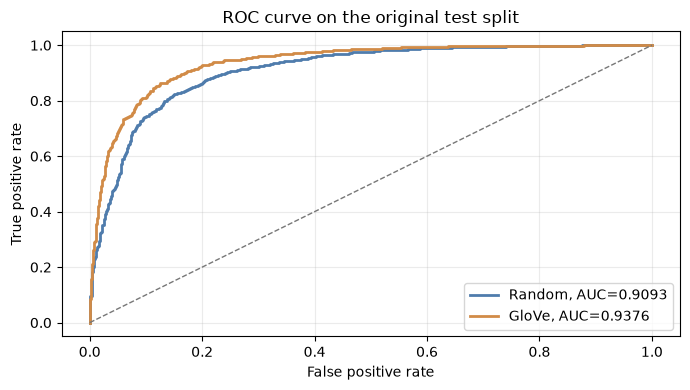

In [12]:
plt.figure(figsize=(7, 4))
for label, key, color in (
    ("Random", "random", "#4f7cac"),
    ("GloVe", "glove", "#d18b47"),
):
    result = random_result if key == "random" else glove_result
    metrics = result["test_metrics"]
    fpr, tpr, _ = roc_curve(metrics["targets"], metrics["probabilities"])
    plt.plot(
        fpr,
        tpr,
        linewidth=2,
        color=color,
        label=f"{label}, AUC={metrics['roc_auc']:.4f}",
    )
plt.plot([0, 1], [0, 1], linestyle="--", color="#777777", linewidth=1)
plt.xlabel("False positive rate")
plt.ylabel("True positive rate")
plt.title("ROC curve on the original test split")
plt.legend()
plt.grid(True, alpha=0.25)
plt.tight_layout()
plt.savefig(ARTIFACT_DIR / "roc_comparison.png", dpi=160, bbox_inches="tight")
plt.show()


In [13]:
import sys


def public_metrics(metrics):
    return {
        key: value
        for key, value in metrics.items()
        if key not in {"targets", "predictions", "probabilities"}
    }


summary = {
    "run_name": "improved_minimal_controlled_experiment",
    "seed": SEED,
    "epochs": EPOCHS,
    "split": {"train": 20000, "validation": 2500, "test": 2500},
    "vocab_size": len(stoi),
    "padding": "pack_padded_sequence",
    "checkpoint_selection": "best validation accuracy",
    "embedding_state": "both frozen",
    "random": {
        **public_metrics(random_result["test_metrics"]),
        "history": random_result["history"],
    },
    "glove": {
        **public_metrics(glove_result["test_metrics"]),
        "history": glove_result["history"],
    },
}
(ARTIFACT_DIR / "metrics.json").write_text(
    json.dumps(summary, indent=2, ensure_ascii=False) + "\n",
    encoding="utf-8",
)

environment = {
    "python": sys.version,
    "torch": torch.__version__,
    "cuda": torch.version.cuda,
    "device": str(DEVICE),
    "gpu": (
        torch.cuda.get_device_name(0)
        if torch.cuda.is_available()
        else None
    ),
}
(ARTIFACT_DIR / "executed_environment.json").write_text(
    json.dumps(environment, indent=2, ensure_ascii=False) + "\n",
    encoding="utf-8",
)

print("Artifacts written to:", ARTIFACT_DIR.resolve())


Artifacts written to: improved/artifacts


## 7. 结论边界

改进版消除了 padding、随机种子、Embedding 可训练状态和 checkpoint 选择带来的
主要混杂因素，但它仍然只使用一个种子、一种 LSTM 结构和一个 10,000 词词表。
因此结果只适用于当前数据划分与训练配置，不能外推成“GloVe 一定更好”或
“随机 Embedding 一定更差”的普遍结论。
